# 0. Gathering the data

Points per game only counts the games a player plays. This project also counts the games he **could** have played: every game his team played while he was on the roster, from his NBA debut on.

This notebook gathers the data and checks it. Seasons 2020-21 to 2025-26, plus 2026-27 (still being played). Regular season only. All data comes from NBA.com.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from nba_api.stats.endpoints import playercareerstats

from xppg import data, plotting
from xppg.raw import fetch, PROJECT_ROOT
from xppg.show import table

plotting.use_style()

# Download (cached after the first run; only the current season is refreshed)
P, T, R = [], [], []
for season in data.SEASONS:
    live = season == data.IN_PROGRESS
    t = data.team_games(season, refresh=live)
    P.append(data.player_games(season, refresh=live))
    T.append(t)
    R.append(data.rosters(season, sorted(t.team_id.unique()), refresh=live))
P, T, R = (pd.concat(x, ignore_index=True) for x in (P, T, R))
M = data.player_movement()
debut = data.debuts()

team_abbr = T.drop_duplicates("team_id").set_index("team_id").team_abbreviation
R["team"] = R.team_id.map(team_abbr)
season_start = T.groupby("season").game_date.min()
season_end = T.groupby("season").game_date.max()
team_dates = T.groupby(["season", "team_id"]).game_date.apply(list)

## 1. How many games each team played

**What you're looking at:** the number of regular-season games every team played in each season.  
**Why it matters:** a player can only miss games his team actually played, so this is the starting point. 2020-21 was cut to 72 games because of COVID-19; 2026-27 is still being played.

In [2]:
games = T.groupby(["season", "team_id"]).size().groupby("season").agg(["min", "max"])
games["Games per team"] = [str(a) if a == b else f"{a} to {b} so far" for a, b in zip(games["min"], games["max"])]
table(games[["Games per team"]].rename_axis("Season"), "Regular-season games per team")

,Games per team
Season,
2020-21,72
2021-22,82
2022-23,82
2023-24,82
2024-25,82
2025-26,82
2026-27,15 to 19 so far


## 2. Joel Embiid, season by season

**What you're looking at:** how many of the 76ers' games Embiid played and missed each season, with his points per game in the games he played.  
**Why it matters:** Embiid is the reason for this project: a superstar scorer who often isn't available. These numbers match NBA.com's official totals exactly.

In [3]:
EMBIID = 203954
career = fetch(playercareerstats.PlayerCareerStats, player_id=EMBIID, per_mode36="Totals")["SeasonTotalsRegularSeason"]
emb = P[P.player_id == EMBIID].groupby("season").agg(gp=("game_id", "nunique"), pts=("pts", "sum"))
emb["team_games"] = T[T.team_abbreviation == "PHI"].groupby("season").size()
emb["missed"] = emb.team_games - emb.gp
emb["ppg"] = emb.pts / emb.gp
assert (emb.pts == career.set_index("SEASON_ID").PTS.reindex(emb.index)).all()  # matches NBA.com
assert career.loc[career.SEASON_ID != "2026-27", "PTS"].sum() == 13544

shown = emb.rename(columns={"team_games": "76ers games", "gp": "Played", "missed": "Missed", "ppg": "Points per game"})
table(shown[["76ers games", "Played", "Missed", "Points per game"]].rename_axis("Season"), "Joel Embiid, regular season")

,76ers games,Played,Missed,Points per game
Season,,,,
2020-21,72,51,21,28.5
2021-22,82,68,14,30.6
2022-23,82,66,16,33.1
2023-24,82,39,43,34.7
2024-25,82,19,63,23.8
2025-26,82,38,44,26.9
2026-27,18,14,4,20.4


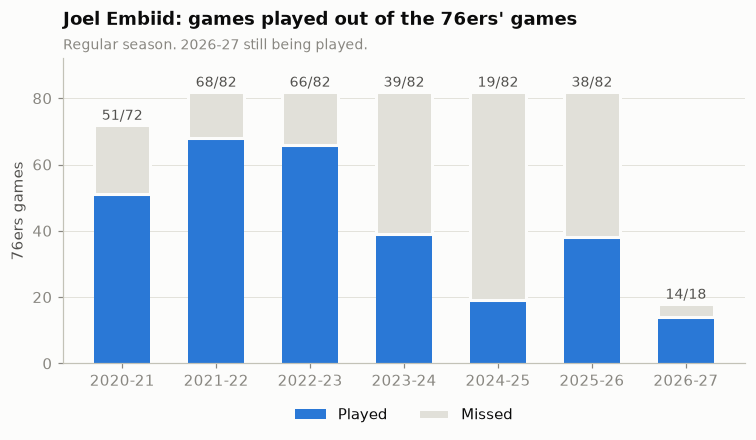

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(emb))
ax.bar(x, emb.gp, color=plotting.SERIES[0], width=0.6, label="Played")
ax.bar(x, emb.missed, bottom=emb.gp, color=plotting.GRID, width=0.6, label="Missed",
       edgecolor=plotting.SURFACE, linewidth=2)
for i, (gp, tg) in enumerate(zip(emb.gp, emb.team_games)):
    ax.text(i, tg + 1.5, f"{gp}/{tg}", ha="center", fontsize=9, color=plotting.INK_2)
ax.set_xticks(list(x), emb.index)
ax.set_ylabel("76ers games")
ax.set_ylim(0, 92)
ax.set_title("Joel Embiid: games played out of the 76ers' games", pad=22)
ax.text(0, 1.03, "Regular season. 2026-27 still being played.", transform=ax.transAxes, color=plotting.MUTED, fontsize=9)
ax.legend(loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.1))
plotting.save(fig, "0_embiid_games");

## 3. Players who missed a whole season

**What you're looking at:** players who were on a team all season but did not play a single game.  
**Why it matters:** points per game cannot see these seasons at all, because there are no games to average. Here they count as 0 points from all of the team's games. Rookies who had not yet played their first NBA game are left out: a player is only counted from his debut.

In [5]:
played = set(zip(P.season, P.player_id))
no_games = R[[(s, p) not in played for s, p in zip(R.season, R.player_id)]].copy()
no_games["debut"] = no_games.player_id.map(debut)
no_games = no_games[(no_games.debut < no_games.season.map(season_start)) & no_games.season.isin(data.COMPLETE_SEASONS)]
whole = (no_games.sort_values(["season", "player_name"])
         .rename(columns={"season": "Season", "player_name": "Player", "team": "Team"})[["Season", "Player", "Team"]])
table(whole.reset_index(drop=True), "On the roster all season, 0 games played")

Season,Player,Team
2020-21,Jonathan Isaac,ORL
2020-21,Klay Thompson,GSW
2020-21,Zach Collins,POR
2021-22,Ben Simmons,BKN
2021-22,Dario Šarić,PHX
2021-22,Jamal Murray,DEN
2021-22,James Wiseman,GSW
2021-22,John Wall,HOU
2021-22,Jonathan Isaac,ORL
2021-22,Kawhi Leonard,LAC


## 4. Following players between teams

**What you're looking at:** every player-season, sorted by what happened to the player during that season.  
**Why it matters:** to count the games a player could have played, we need to know when he was on each team. That is easy for players who stayed put all season. For players who were traded, waived or released, the game records alone don't show the dates.

In [6]:
Pc = P[P.season.isin(data.COMPLETE_SEASONS)]
cases = (Pc.sort_values("game_date").groupby(["season", "player_id"])
           .agg(teams=("team_id", "nunique"), last_team=("team_id", "last"), last_game=("game_date", "max"))
           .reset_index())
on_roster = set(zip(R.season, R.player_id, R.team_id))
cases["stayed"] = [(s, p, t) in on_roster for s, p, t in zip(cases.season, cases.player_id, cases.last_team)]
cases["What happened"] = "Played for two or more teams"
cases.loc[(cases.teams == 1) & cases.stayed, "What happened"] = "Stayed with one team all season"
cases.loc[(cases.teams == 1) & ~cases.stayed, "What happened"] = "Waived or released during the season"
kinds = pd.crosstab(cases.season, cases["What happened"], margins=True, margins_name="All seasons")
kinds = kinds[["Stayed with one team all season", "Played for two or more teams", "Waived or released during the season", "All seasons"]]
table(kinds.rename_axis(index="Season", columns=None), "Player-seasons by what happened, 2020-21 to 2025-26")

,Stayed with one team all season,Played for two or more teams,Waived or released during the season,All seasons
Season,,,,
2020-21,420,79,41,540
2021-22,411,97,97,605
2022-23,427,70,42,539
2023-24,447,78,47,572
2024-25,446,81,42,569
2025-26,454,72,56,582
All seasons,"2,605",477,325,"3,407"


## 5. An example: Kevin Durant's trade to Phoenix

**What you're looking at:** Durant's last game for Brooklyn, the date of his trade, and his first game for Phoenix in 2022-23.  
**Why it matters:** he was injured for that whole stretch, so those games should count as missed. The game records only show when he played; NBA.com's list of transactions gives the trade date, so each missed game goes to the right team.

In [7]:
DURANT = 201142
d = P[(P.player_id == DURANT) & (P.season == "2022-23")]
bkn, phx = d[d.team_abbreviation == "BKN"], d[d.team_abbreviation == "PHX"]
trade = M[(M.player_id == DURANT) & (M.type == "Trade") & (M.date.dt.year == 2023)].date.iloc[0]
last_bkn, first_phx = bkn.game_date.max(), phx.game_date.min()
bkn_id, phx_id = bkn.team_id.iloc[0], phx.team_id.iloc[0]
missed_bkn = sum(last_bkn < x <= trade for x in team_dates[("2022-23", bkn_id)])
missed_phx = sum(trade < x < first_phx for x in team_dates[("2022-23", phx_id)])
timeline = pd.DataFrame({
    "Date": [last_bkn.date(), trade.date(), first_phx.date()],
    "Games missed since the step before": ["", f"{missed_bkn} Nets games", f"{missed_phx} Suns games"],
}, index=["Last game for Brooklyn", "Traded to Phoenix", "First game for Phoenix"])
table(timeline.rename_axis("2022-23"), "Kevin Durant: from Brooklyn to Phoenix")

,Date,Games missed since the step before
2022-23,,
Last game for Brooklyn,2023-01-08,
Traded to Phoenix,2023-02-09,15 Nets games
First game for Phoenix,2023-03-01,5 Suns games


## 6. Can we date every move?

**What you're looking at:** for every player who was waived, released or changed teams, whether we know when it happened.  
**Why it matters:** NBA.com's list of transactions dates nearly all of them. A 10-day contract ends 10 days after it was signed. The few with no date are marked, so they can be checked or left out.

In [8]:
gone = cases[cases["What happened"] == "Waived or released during the season"].copy()

def exit_source(r):
    after = M[(M.player_id == r.player_id) & (M.date >= r.last_game) & (M.date <= season_end[r.season])]
    if after.type.isin(["Waive", "Trade"]).any():
        return "Dated by a transaction"
    signed = M[(M.player_id == r.player_id) & (M.date <= r.last_game) & M.contract.notna()]
    if len(signed) and signed.contract.iloc[-1] == "10-Day Contract":
        return "10-day contract: ends 10 days after signing"
    return "No date: marked"

spans = (Pc.groupby(["season", "player_id", "team_id"]).game_date.agg(["min", "max"])
           .reset_index().sort_values(["season", "player_id", "min"]))
changes = []
for (season, pid), s in spans.groupby(["season", "player_id"]):
    s = s.reset_index(drop=True)
    for i in range(1, len(s)):
        dated = ((M.player_id == pid) & (M.date >= s.loc[i - 1, "max"]) & (M.date <= s.loc[i, "min"])
                 & M.type.isin(["Trade", "Waive", "Signing", "AwardOnWaivers"])).any()
        changes.append("Dated by a transaction" if dated else "No date: marked")

dating = pd.concat({
    "Waived or released": gone.apply(exit_source, axis=1).value_counts(),
    "Changed teams": pd.Series(changes).value_counts(),
}, axis=1).fillna(0).astype(int)
dating = dating.loc[["Dated by a transaction", "10-day contract: ends 10 days after signing", "No date: marked"]]
table(dating.rename_axis("How we know the date"), "Dating every move, 2020-21 to 2025-26")

,Waived or released,Changed teams
How we know the date,,
Dated by a transaction,191,509
10-day contract: ends 10 days after signing,125,0
No date: marked,9,6


---
Every rule used here is listed, with its reason, in `docs/DECISIONS.md`.

In [9]:
# Save the tables for later notebooks (data/ is not in git)
out = PROJECT_ROOT / "data" / "processed"
P.to_parquet(out / "player_games.parquet", index=False)
T.to_parquet(out / "team_games.parquet", index=False)
R.to_parquet(out / "rosters.parquet", index=False)
M.to_parquet(out / "player_movement.parquet", index=False)
debut.reset_index().to_parquet(out / "debuts.parquet", index=False)